<a href="https://colab.research.google.com/github/JuanBeltran0397/Proyecto_Programacion_Analisis_Datos_Totto/blob/rama_automatizacion/Pruebas_EA1_Proyecto_Totto_Analisis_Categorias_Productos_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evidencia de aprendizaje 1 — Web scraping y análisis de Totto Colombia
**Fuente:** https://co.totto.com/  
**Objetivo:** inventariar categorías y subcategorías públicas, extraer fichas de productos y analizar precios, descuentos, marcas, disponibilidad y atributos.  
**Advertencia:** el sitio puede restringir consultas automatizadas. Este cuaderno no evade bloqueos, CAPTCHA ni autenticación; detiene la extracción ante respuestas 403/429. Los resultados son observaciones del catálogo público en la fecha de ejecución, no ventas reales.

In [ ]:
# Importación de bibliotecas necesarias para scraping, manipulación de datos y visualización
import requests, pandas as pd, numpy as np, re, time, json, random, matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from datetime import datetime, timezone
from IPython.display import display

# Definición de la URL base del sitio web
BASE='https://co.totto.com'

# Configuración de la sesión HTTP con un User-Agent identificativo
S=requests.Session(); S.headers.update({'User-Agent':'ProyectoAcademicoColab/1.0 (investigacion educativa; contacto por navegador)', 'Accept':'application/json, text/html;q=0.9'})
PAUSA=1.5
FECHA=datetime.now().astimezone().isoformat(timespec='seconds')

# Función auxiliar para realizar peticiones HTTP de forma segura y respetando los límites del servidor
def obtener(url, params=None):
    try:
        r=S.get(url,params=params,timeout=25)
        if r.status_code in (403,429):
            print(f'Acceso limitado ({r.status_code}) en {r.url}. Se detiene esta consulta; no se intentará eludir la restricción.')
            return None
        r.raise_for_status(); time.sleep(PAUSA); return r
    except requests.RequestException as e:
        print('Error de acceso:',str(e)[:180]); return None

print('Fecha de captura:',FECHA)

Fecha de captura: 2026-11-08T19:08:18+00:00


## 1. Descubrimiento de pestañas y categorías
Totto muestra menús como **Morrales, Mujer, Hombre, Niña, Niño, Viaje, Mascotas, Personajes y Accesorios**. El cuaderno intenta obtener la jerarquía completa desde el catálogo público VTEX; si no está disponible, usa enlaces visibles de navegación como respaldo. No confundir campañas temporales con categorías permanentes.

In [ ]:
# Consulta del árbol de categorías principal mediante la API pública de VTEX
r=obtener(BASE+'/api/catalog_system/pub/category/tree/5')
jerarquia=[]
if r is not None:
    try: jerarquia=r.json() if isinstance(r.json(),list) else []
    except ValueError: pass

# Función recursiva para aplanar la estructura jerárquica de las categorías
def aplanar(nodos,padre='',nivel=1):
    filas=[]
    for x in nodos:
        nombre=x.get('name',''); ruta=x.get('url','')
        filas.append({'categoria':nombre,'categoria_padre':padre,'nivel':nivel,'id_categoria':x.get('id'),'url_categoria':urljoin(BASE,ruta) if ruta else None})
        filas.extend(aplanar(x.get('children') or [],nombre,nivel+1))
    return filas

categorias=pd.DataFrame(aplanar(jerarquia))

# Mecanismo de respaldo: si la API falla, se extraen enlaces visibles desde la página principal
if categorias.empty:
    r=obtener(BASE)
    if r is not None:
        sopa=BeautifulSoup(r.text,'html.parser'); candidatos=[]
        for a in sopa.select('a[href]'):
            href=urljoin(BASE,a['href']); nombre=a.get_text(' ',strip=True)
            if href.startswith(BASE+'/') and nombre and len(nombre)<60:
                candidatos.append({'categoria':nombre,'categoria_padre':'Navegación visible','nivel':1,'id_categoria':None,'url_categoria':href.split('?')[0]})
        categorias=pd.DataFrame(candidatos).drop_duplicates(subset=['url_categoria']) if candidatos else pd.DataFrame(columns=['categoria','categoria_padre','nivel','id_categoria','url_categoria'])

print('Categorías y subcategorías identificadas:',len(categorias)); display(categorias.head(35))

Categorías y subcategorías identificadas: 269


,categoria,categoria_padre,nivel,id_categoria,url_categoria
0,Hombre,,1,1,https://co.totto.com/hombre
1,Accesorios,Hombre,2,14,https://co.totto.com/hombre/accesorios
2,billeteras,Accesorios,3,65,https://co.totto.com/hombre/accesorios/billeteras
3,gorras,Accesorios,3,66,https://co.totto.com/hombre/accesorios/gorras
4,gorros-para-hombre,Accesorios,3,67,https://co.totto.com/hombre/accesorios/gorros-...
5,cartucheras,Accesorios,3,68,https://co.totto.com/hombre/accesorios/cartuch...
6,loncheras,Accesorios,3,69,https://co.totto.com/hombre/accesorios/loncheras
7,canguros,Accesorios,3,70,https://co.totto.com/hombre/accesorios/canguros
8,gafas-de-sol,Accesorios,3,71,https://co.totto.com/hombre/accesorios/gafas-d...
9,relojes,Accesorios,3,72,https://co.totto.com/hombre/accesorios/relojes


## 2. Recolección por categoría, con paginación y control de carga
La API pública de búsqueda VTEX, cuando esté habilitada, permite recuperar registros con nombres, referencias, descripciones, categorías, precios e inventario público. Se aplica un **límite configurable** para evitar consultas masivas; cada categoría se procesa de forma independiente. Si la API no responde, el resultado quedará vacío y se documentará la limitación en vez de fabricar registros.

In [ ]:
MAX_CATEGORIAS=30       # Ajusta después de comprobar permisos
MAX_PRODUCTOS_CATEGORIA=100  # 2 páginas de hasta 50
TAM_LOTE=50
# Solo categorías principales por defecto. Cambia a False para incluir subcategorías (más solicitudes y duplicados).
SOLO_PRINCIPALES=True
seleccion=categorias[categorias['nivel'].eq(1)].copy() if SOLO_PRINCIPALES else categorias.copy()
seleccion=seleccion.head(MAX_CATEGORIAS)
print('Categorías a procesar:',len(seleccion))

Categorías a procesar: 18


In [ ]:
def precio_de_item(item):
    sellers=item.get('sellers') or []
    oferta=(sellers[0].get('commertialOffer') or {}) if sellers else {}
    return oferta.get('Price'),oferta.get('ListPrice'),oferta.get('AvailableQuantity'),oferta.get('IsAvailable')

def registro(p, categoria_consulta):
    items=p.get('items') or []
    item=items[0] if items else {}
    precio,lista,stock,disponible=precio_de_item(item)
    specs={}
    for g in p.get('specificationGroups') or []:
        for s in g.get('specifications') or []:
            specs[s.get('name','')]=', '.join(map(str,s.get('values') or []))
    return {'id_producto':p.get('productId'),'referencia':p.get('productReference'),'nombre':p.get('productName'),
      'marca':p.get('brand'),'categoria_consulta':categoria_consulta,'categorias_producto':' | '.join(p.get('categories') or []),
      'descripcion':BeautifulSoup(p.get('description') or '','html.parser').get_text(' ',strip=True),
      'precio_cop':precio,'precio_lista_cop':lista,'stock_publicado':stock,'disponible':disponible,
      'sku':item.get('itemId'),'ean':item.get('ean'),'atributos_json':json.dumps(specs,ensure_ascii=False),
      'url_producto':urljoin(BASE,p.get('link') or ''),'url_imagen':((item.get('images') or [{}])[0]).get('imageUrl'),
      'fecha_captura':FECHA}

registros=[]; estado=[]; detener=False
for _,cat in seleccion.iterrows():
    nombre=str(cat['categoria']); ident=cat['id_categoria']; ruta=cat['url_categoria']
    if pd.notna(ident):
        endpoint=BASE+'/api/catalog_system/pub/products/search/'
        filtro={'fq':'C:'+str(int(ident))}
    else:
        # Respaldo: ruta de categoría VTEX. Puede no funcionar para todas las tiendas.
        endpoint=BASE+'/api/catalog_system/pub/products/search/'
        filtro={'fq':'H:'+str(ruta).replace(BASE+'/','')}
    encontrados=0; motivo='OK'
    for inicio in range(0,MAX_PRODUCTOS_CATEGORIA,TAM_LOTE):
        params={**filtro,'_from':inicio,'_to':min(inicio+TAM_LOTE-1,MAX_PRODUCTOS_CATEGORIA-1)}
        r=obtener(endpoint,params)
        if r is None:
            motivo='API no accesible o bloqueada'; break
        try: productos=r.json()
        except ValueError: motivo='Respuesta no JSON'; break
        if not isinstance(productos,list): motivo='Formato no esperado'; break
        for p in productos: registros.append(registro(p,nombre))
        encontrados+=len(productos)
        if len(productos)<TAM_LOTE: break
    estado.append({'categoria':nombre,'productos_recuperados':encontrados,'estado':motivo})
    if motivo!='OK' and encontrados==0:
        print('Categoría sin acceso:',nombre, motivo)
productos=pd.DataFrame(registros)
log=pd.DataFrame(estado)
print('Filas recopiladas:',len(productos)); display(log); display(productos.head() if not productos.empty else pd.DataFrame({'aviso':['No se extrajeron productos. Verificar el estado de acceso; no hay datos para analizar.']}))

Filas recopiladas: 1232


,categoria,productos_recuperados,estado
0,Hombre,100,OK
1,Mujer,100,OK
2,nino,100,OK
3,Morrales,100,OK
4,Accesorios,100,OK
5,viaje,100,OK
6,Proteccion,0,OK
7,Hogar,0,OK
8,Mascotas,32,OK
9,Somos-Colombia,0,OK


,id_producto,referencia,nombre,marca,categoria_consulta,categorias_producto,descripcion,precio_cop,precio_lista_cop,stock_publicado,disponible,sku,ean,atributos_json,url_producto,url_imagen,fecha_captura
0,36045,MA04TCX002-26100-N01,"Morral Universitario Tocaxu Plus Porta PC 15"" ...",Totto,Hombre,/unisex/ | /Mujer/ | /Mujer/Morrales/ | /Hombr...,El morral Tocaxu Plus está fabricado en poliam...,77994.0,129990.0,99999,True,66982,7704682198934,{},https://co.totto.com/morral-universitario-toca...,https://tottoco.vteximg.com.br/arquivos/ids/67...,2026-11-08T12:03:05+00:00
1,36026,AC50HIL002-2610Z-N01,Riñonera Unisex Chill Mediana color Negro,Totto,Hombre,/unisex/ | /Hombre/ | /Hombre/Accesorios/ | /H...,El canguro mediano Chill con doble bolsillo es...,69990.0,69990.0,100,True,66963,7704682202860,{},https://co.totto.com/rinonera-unisex-chill-med...,https://tottoco.vteximg.com.br/arquivos/ids/66...,2026-11-08T12:03:05+00:00
2,35861,MA04IND962-26100-Z9G,"Morral Ejecutivo Porta PC 14"" Osaka Azul Unisex",Totto,Hombre,/unisex/ | /Mujer/ | /Mujer/Morrales/ | /Hombr...,¡Lleva tu equipo con comodidad y funcionalidad...,103992.0,129990.0,99999,True,66777,7704682193120,{},https://co.totto.com/morral-ejecutivo-porta-pc...,https://tottoco.vteximg.com.br/arquivos/ids/67...,2026-11-08T12:03:05+00:00
3,35693,MA04TKI005-26160-N01,"Morral Universitario Trik 2.0 Porta PC 14"" Negro",Totto,Hombre,/unisex/ | /Mujer/ | /Mujer/Morrales/ | /Hombr...,El morral universitario Trik 2.0 integra un co...,99990.0,99990.0,99999,True,66609,7704682209302,{},https://co.totto.com/morral-universitario-trik...,https://tottoco.vteximg.com.br/arquivos/ids/67...,2026-11-08T12:03:05+00:00
4,35147,MA04TCX001-26100-N01,"Morral Universitario Tocaxu Porta PC 15"" Negro",Totto,Hombre,/unisex/ | /Mujer/ | /Mujer/Morrales/ | /Hombr...,¡Elígelo porque será tu mejor aliado! El morra...,71994.0,119990.0,99999,True,65625,7704682198880,{},https://co.totto.com/morral-universitario-toca...,https://tottoco.vteximg.com.br/arquivos/ids/65...,2026-11-08T12:03:05+00:00


## 3. Limpieza y variables derivadas
Un mismo producto puede aparecer en varias pestañas. Se conserva una tabla de apariciones por categoría y una tabla única por identificador. Los precios nulos **no** se reemplazan por cero.

In [ ]:
if not productos.empty:
    productos['precio_cop']=pd.to_numeric(productos['precio_cop'],errors='coerce')
    productos['precio_lista_cop']=pd.to_numeric(productos['precio_lista_cop'],errors='coerce')
    productos['descuento_pct']=np.where((productos['precio_lista_cop']>0)&(productos['precio_cop'].notna()),
       (1-productos['precio_cop']/productos['precio_lista_cop'])*100,np.nan)
    productos['descuento_pct']=productos['descuento_pct'].clip(lower=0,upper=100)
    unicos=productos.drop_duplicates(subset=['id_producto']).copy()
    print('Productos únicos:',len(unicos),'| Apariciones en categorías:',len(productos))
    display(unicos[['nombre','precio_cop','precio_lista_cop','descuento_pct','disponible']].head(15))
else:
    unicos=productos.copy()
    print('Sin datos reales; se omiten cálculos para evitar conclusiones ficticias.')

Productos únicos: 877 | Apariciones en categorías: 1232


,nombre,precio_cop,precio_lista_cop,descuento_pct,disponible
0,"Morral Universitario Tocaxu Plus Porta PC 15"" ...",77994.0,129990.0,40.0,True
1,Riñonera Unisex Chill Mediana color Negro,69990.0,69990.0,0.0,True
2,"Morral Ejecutivo Porta PC 14"" Osaka Azul Unisex",103992.0,129990.0,20.0,True
3,"Morral Universitario Trik 2.0 Porta PC 14"" Negro",99990.0,99990.0,0.0,True
4,"Morral Universitario Tocaxu Porta PC 15"" Negro",71994.0,119990.0,40.0,True
5,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Azul...",119992.0,149990.0,20.0,True
6,"Morral Ejecutivo Porta PC 14"" Osaka Negro Unisex",103992.0,129990.0,20.0,True
7,Morral Plegable Ligero Troker Mediano Negro,59990.0,59990.0,0.0,True
8,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Negr...",119992.0,149990.0,20.0,True
9,"Morral Universitario Cloud Porta PC 14"" Azul",129990.0,129990.0,0.0,True


## 4. Análisis de **cada pestaña/categoría**
Para cada categoría: cantidad de registros, productos únicos, mínimo, máximo, mediana, promedio, descuentos, disponibilidad y distribución de precios. Se genera además un texto automático por categoría basado **solo** en datos observados.

In [ ]:
if not productos.empty:
    resumen=(productos.groupby('categoria_consulta',dropna=False).agg(
        registros=('id_producto','size'),productos_unicos=('id_producto','nunique'),
        precio_min=('precio_cop','min'),precio_mediano=('precio_cop','median'),precio_promedio=('precio_cop','mean'),
        precio_max=('precio_cop','max'),descuento_promedio_pct=('descuento_pct','mean'),
        disponibles=('disponible',lambda x: int((x==True).sum()))).reset_index())
    resumen['porcentaje_disponibles']=100*resumen['disponibles']/resumen['registros']
    display(resumen.sort_values('productos_unicos',ascending=False))
    for _,x in resumen.iterrows():
        print(f"{x['categoria_consulta']}: {int(x['productos_unicos'])} productos únicos; precio mediano COP ${x['precio_mediano']:,.0f}; rango COP ${x['precio_min']:,.0f}–${x['precio_max']:,.0f}; descuento promedio {x['descuento_promedio_pct']:.1f}% (si está disponible).")
else:
    resumen=pd.DataFrame(); print('No es posible analizar categorías sin registros extraídos.')

,categoria_consulta,registros,productos_unicos,precio_min,precio_mediano,precio_promedio,precio_max,descuento_promedio_pct,disponibles,porcentaje_disponibles
0,Accesorios,100,100,1077.0,39991.0,40427.07000,199990.0,38.700000,99,99.00
1,Bolsos,100,100,39995.0,119990.0,125650.23000,229990.0,2.300000,100,100.00
2,Hombre,100,100,1077.0,71994.0,79997.86000,279990.0,26.600000,96,96.00
4,Morrales,100,100,59990.0,111993.0,135002.31000,329990.0,23.100000,100,100.00
5,Mujer,100,100,1077.0,69991.5,76534.78000,229990.0,29.749997,94,94.00
9,parches,100,100,2590.0,2590.0,2713.10000,14900.0,0.000000,100,100.00
6,Ropa,100,100,41994.0,129990.0,133755.23000,249990.0,12.300000,71,71.00
7,nina,100,100,1077.0,3590.0,31952.29000,299990.0,12.900000,100,100.00
8,nino,100,100,1077.0,14997.0,48089.95000,299990.0,19.500000,99,99.00
11,unisex,100,100,1077.0,49491.5,52882.33000,249990.0,23.300000,100,100.00


Accesorios: 100 productos únicos; precio mediano COP $39,991; rango COP $1,077–$199,990; descuento promedio 38.7% (si está disponible).
Bolsos: 100 productos únicos; precio mediano COP $119,990; rango COP $39,995–$229,990; descuento promedio 2.3% (si está disponible).
Hombre: 100 productos únicos; precio mediano COP $71,994; rango COP $1,077–$279,990; descuento promedio 26.6% (si está disponible).
Mascotas: 32 productos únicos; precio mediano COP $49,995; rango COP $9,995–$164,995; descuento promedio 47.7% (si está disponible).
Morrales: 100 productos únicos; precio mediano COP $111,993; rango COP $59,990–$329,990; descuento promedio 23.1% (si está disponible).
Mujer: 100 productos únicos; precio mediano COP $69,992; rango COP $1,077–$229,990; descuento promedio 29.7% (si está disponible).
Ropa: 100 productos únicos; precio mediano COP $129,990; rango COP $41,994–$249,990; descuento promedio 12.3% (si está disponible).
nina: 100 productos únicos; precio mediano COP $3,590; rango COP $1

## 5. Análisis individual de **cada producto**
Se produce una ficha por producto con categoría, SKU, descripción, precio, descuento, disponibilidad, atributos técnicos y enlace. Para evitar saturar la pantalla, se muestra una muestra y se exportan **todas** las fichas a Excel/CSV.

In [ ]:
if not unicos.empty:
    fichas=unicos.copy()
    fichas['analisis_individual']=fichas.apply(lambda x: (
        f"Producto: {x['nombre']}. Categorías: {x['categorias_producto']}. "
        f"Precio publicado: {('COP $'+format(x['precio_cop'],',.0f')) if pd.notna(x['precio_cop']) else 'no disponible'}. "
        f"Descuento: {format(x['descuento_pct'],'.1f')+'%' if pd.notna(x['descuento_pct']) else 'sin dato verificable'}. "
        f"Disponibilidad publicada: {x['disponible']}. "
        f"Descripción: {(x['descripcion'] or '')[:350]}. "
        f"Especificaciones: {x['atributos_json'][:400]}."),axis=1)
    display(fichas[['nombre','categoria_consulta','precio_cop','analisis_individual']].head(10))
else: fichas=unicos.copy()

,nombre,categoria_consulta,precio_cop,analisis_individual
0,"Morral Universitario Tocaxu Plus Porta PC 15"" ...",Hombre,77994.0,Producto: Morral Universitario Tocaxu Plus Por...
1,Riñonera Unisex Chill Mediana color Negro,Hombre,69990.0,Producto: Riñonera Unisex Chill Mediana color ...
2,"Morral Ejecutivo Porta PC 14"" Osaka Azul Unisex",Hombre,103992.0,"Producto: Morral Ejecutivo Porta PC 14"" Osaka ..."
3,"Morral Universitario Trik 2.0 Porta PC 14"" Negro",Hombre,99990.0,Producto: Morral Universitario Trik 2.0 Porta ...
4,"Morral Universitario Tocaxu Porta PC 15"" Negro",Hombre,71994.0,Producto: Morral Universitario Tocaxu Porta PC...
5,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Azul...",Hombre,119992.0,"Producto: Morral Ejecutivo Porta PC 16"" Wivett..."
6,"Morral Ejecutivo Porta PC 14"" Osaka Negro Unisex",Hombre,103992.0,"Producto: Morral Ejecutivo Porta PC 14"" Osaka ..."
7,Morral Plegable Ligero Troker Mediano Negro,Hombre,59990.0,Producto: Morral Plegable Ligero Troker Median...
8,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Negr...",Hombre,119992.0,"Producto: Morral Ejecutivo Porta PC 16"" Wivett..."
9,"Morral Universitario Cloud Porta PC 14"" Azul",Hombre,129990.0,Producto: Morral Universitario Cloud Porta PC ...


## 6. Visualizaciones e interpretación
Las gráficas reflejan únicamente productos recuperados, no el catálogo completo salvo que se compruebe cobertura exhaustiva.

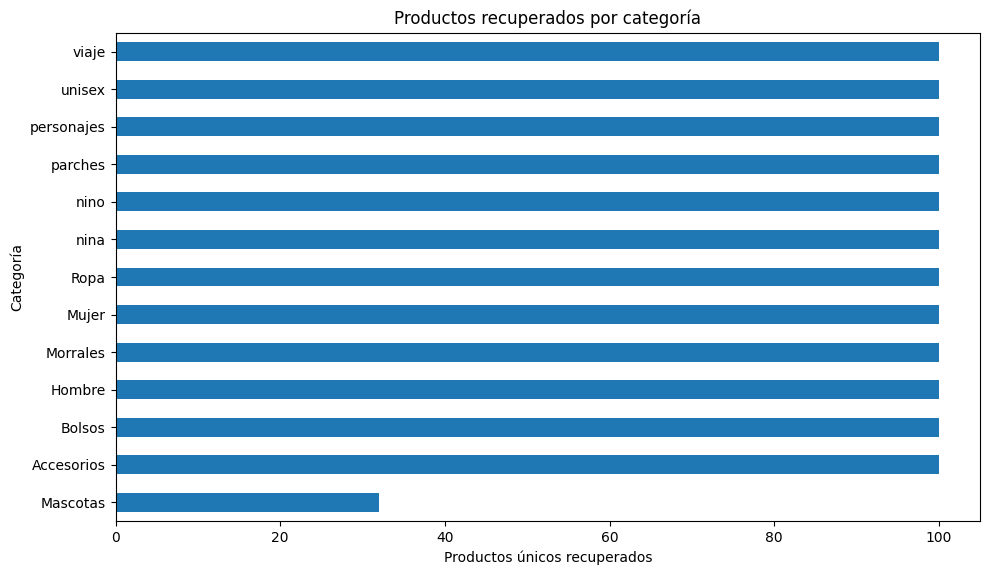

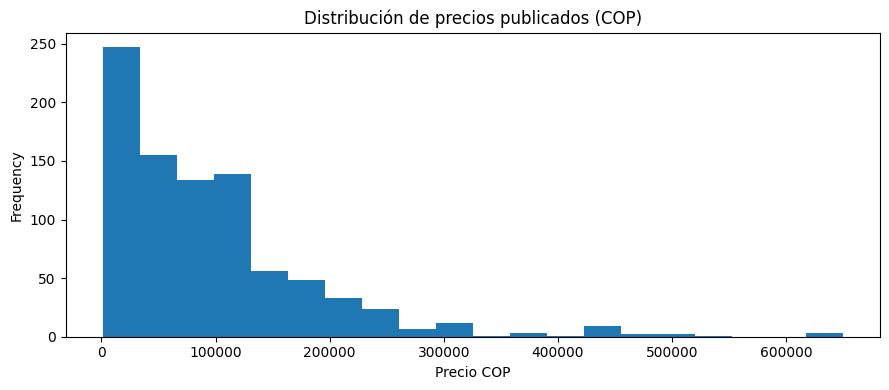

In [ ]:
if not resumen.empty:
    ax=resumen.sort_values('productos_unicos').plot.barh(x='categoria_consulta',y='productos_unicos',legend=False,figsize=(10,max(4,len(resumen)*.45)))
    ax.set(xlabel='Productos únicos recuperados',ylabel='Categoría',title='Productos recuperados por categoría');plt.tight_layout();plt.show()
    datos=unicos.dropna(subset=['precio_cop'])
    if not datos.empty:
        datos['precio_cop'].plot.hist(bins=min(20,max(5,len(datos)//5)),figsize=(9,4),title='Distribución de precios publicados (COP)')
        plt.xlabel('Precio COP');plt.tight_layout();plt.show()
else: print('Gráficos no generados: extracción sin resultados.')

## 7. Exportación y conclusiones
Se exportan los datos sin inventar resultados. El archivo `totto_analisis.xlsx` incluye pestañas para categorías, apariciones de productos, fichas individuales, resumen y estado de las consultas. Los registros corresponden a la fecha indicada y pueden cambiar.

In [ ]:
with pd.ExcelWriter('totto_analisis.xlsx',engine='openpyxl') as w:
    categorias.to_excel(w,'Mapa_categorias',index=False)
    log.to_excel(w,'Estado_extraccion',index=False)
    productos.to_excel(w,'Productos_por_categoria',index=False)
    fichas.to_excel(w,'Fichas_por_producto',index=False)
    resumen.to_excel(w,'Resumen_categorias',index=False)
productos.to_csv('totto_productos.csv',index=False,encoding='utf-8-sig')
print('Archivos generados: totto_analisis.xlsx, totto_productos.csv')
try:
    from google.colab import files
    files.download('totto_analisis.xlsx'); files.download('totto_productos.csv')
except ImportError: print('Descarga los archivos desde el explorador del entorno.')

/tmp/ipykernel_698/4119692650.py:2: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  categorias.to_excel(w,'Mapa_categorias',index=False)
/tmp/ipykernel_698/4119692650.py:3: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  log.to_excel(w,'Estado_extraccion',index=False)
/tmp/ipykernel_698/4119692650.py:4: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  productos.to_excel(w,'Productos_por_categoria',index=False)
/tmp/ipykernel_698/4119692650.py:5: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  fichas.to_excel(w,'Fichas_por_producto',index=False)
/tmp/ipykernel_698/4119692650.py:6: FutureWarning: Starting with pandas version 3.0 all argume

Archivos generados: totto_analisis.xlsx, totto_productos.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Analisis de un producto del catalogo
Se filtra el articulo Morral ejecutivo en el cual se encontró 17 referencias. todas con disponibilidad publicada «Sí». Los precios observados oscilan entre  84.900   y 319.900; la mediana es 149.900  y el promedio  162.900. De las 17 referencias. 13 muestran descuentos positivos y 4 figuran sin descuento; el mayor descuento registrado es 50.0%.

In [ ]:
import pandas as pd
from IPython.display import display

# Filtrar productos únicos que contengan 'ejecutivo' en el nombre o descripción
filtro_ejecutivos = unicos['nombre'].str.contains('ejecutivo', case=False, na=False) | unicos['descripcion'].str.contains('ejecutivo', case=False, na=False)
morrales_ejecutivos = unicos[filtro_ejecutivos].copy()

# Seleccionar y renombrar las columnas solicitadas incluyendo la categoría de consulta
tabla_ejecutivos = morrales_ejecutivos[[
    'nombre',
    'categoria_consulta',
    'descripcion',
    'precio_cop',
    'descuento_pct',
    'disponible'
]].copy()

# Dar un formato amigable a las columnas para la visualización
tabla_ejecutivos['precio_cop'] = tabla_ejecutivos['precio_cop'].apply(lambda x: f"COP ${x:,.0f}" if pd.notna(x) else "No disponible")
tabla_ejecutivos['descuento_pct'] = tabla_ejecutivos['descuento_pct'].apply(lambda x: f" {x:.1f}%" if pd.notna(x) and x > 0 else "Sin descuento")
tabla_ejecutivos['disponible'] = tabla_ejecutivos['disponible'].map({True: 'Sí', False: 'No'})

tabla_ejecutivos.columns = ['Nombre', 'Categoría de Consulta', 'Descripción', 'Precio', 'Descuento', 'Disponible']

print(f'Se encontraron {len(tabla_ejecutivos)} morrales ejecutivos.')
display(tabla_ejecutivos)

Se encontraron 17 morrales ejecutivos.


,Nombre,Categoría de Consulta,Descripción,Precio,Descuento,Disponible
2,"Morral Ejecutivo Porta PC 14"" Osaka Azul Unisex",Hombre,¡Lleva tu equipo con comodidad y funcionalidad...,"COP $103,992",20.0%,Sí
5,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Azul...",Hombre,¡Eleva tu experiencia laboral con este morral ...,"COP $119,992",20.0%,Sí
6,"Morral Ejecutivo Porta PC 14"" Osaka Negro Unisex",Hombre,¡Lleva tu equipo con comodidad y funcionalidad...,"COP $103,992",20.0%,Sí
8,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Negr...",Hombre,¡Eleva tu experiencia laboral con este morral ...,"COP $119,992",20.0%,Sí
36,"Morral Ejecutivo Porta PC 13"" Datar 2.0 Azul H...",Hombre,¡Ligero y cómodo para tus jornadas! El morral ...,"COP $101,994",40.0%,Sí
48,"Morral Ejecutivo Porta PC 16"" Slant Negro Hombre",Hombre,¡Optimiza tu rutina diaria con este morral par...,"COP $249,990",Sin descuento,Sí
49,"Morral Ejecutivo Porta PC 16"" Dallas Negro Hombre",Hombre,Lleva tu morral para oficina Dallas todos los ...,"COP $183,992",20.0%,Sí
51,"Morral Ejecutivo Porta PC 14"" Wivetto Negro Ho...",Hombre,¡Lleva todo lo que necesites a tu trabajo o un...,"COP $149,990",Sin descuento,Sí
174,"Morral Ejecutivo Porta PC 14"" Adelaide 1 2.0 M...",Mujer,¡Organiza tu día con Adelaide 1 2.0! Este morr...,"COP $223,992",20.0%,Sí
392,"Morral Ejecutivo Porta PC 16"" Gtx 3.0 Negro Ho...",Morrales,"Avanza seguro con el Gtx 3.0, un morral para o...","COP $319,990",Sin descuento,Sí


**Ética y límites:** usar solamente datos públicos; no recolectar datos personales, no eludir medidas de seguridad, revisar términos del sitio y respetar límites de consulta. Si el acceso es denegado, solicitar autorización o utilizar un conjunto de datos autorizado.

**Referencias (APA 7):**
* Totto. (2026). *Tienda oficial Totto Colombia*. https://co.totto.com/
* Python Software Foundation. (s. f.). *Python documentation*. https://docs.python.org/3/
* Pandas development team. (s. f.). pandas documentation. https://pandas.pydata.org/docs/
* Beautiful Soup. (s. f.). Beautiful Soup documentation. https://www.crummy.com/software/BeautifulSoup/bs4/doc/
* Project Jupyter. (s. f.). Jupyter documentation. https://docs.jupyter.org/




